# SentinelOps SOC Alert-Triage Module - Experiments
**CSA06 Design and Analysis of Algorithms - CO2 Debugging and Optimisation Task**  
Shaik Shahid - 192424311

This notebook runs every experiment of part (d): correctness on the question's test data, then operation counts and run times for
sorting, blocklist lookup, signature search and closest pair.  Run all cells from top to bottom (about one minute).
It uses the same functions and the same random seed (2026) as `experiments.py`.  Counts are identical every time; run times change a little from machine to machine.
Its own output files go to `Supporting_Files/notebook_run/` so the results used in the report are not overwritten.

In [1]:
import sys, math
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd()))          # the notebook lives in Source_Code/
import original_module as orig
import corrected_module as cor
import optimised_module as opt
import experiments as ex

# keep this notebook's own results separate from the ones used in the report
ex.ROOT = Path.cwd().parent / "Supporting_Files" / "notebook_run"
for sub in ("results", "graphs"):
    (ex.ROOT / sub).mkdir(parents=True, exist_ok=True)
print("seed:", ex.SEED)

seed: 2026


## 1. Correctness on the question's test data
The same input is given to the original, the corrected and the optimised functions.

In [2]:
alerts = [("A1", 3), ("A2", 9), ("A3", 5), ("A4", 9), ("A5", 1)]
blocklist = ["10.0.0.5", "10.0.0.9", "172.16.4.2"]
queries = ["10.0.0.9", "10.0.0.5", "8.8.8.8"]
log, pattern = "FAILFAIXFAIL", "FAIL"
events = [(2, 3), (12, 30), (40, 50), (5, 1), (12, 10), (3, 4)]
index = opt.build_blocklist(blocklist)

table = pd.DataFrame({
    "function": ["sort_alerts", "is_blocked (3 queries)", "find_signature", "closest_logins"],
    "expected": [
        "[A2:9, A4:9, A3:5, A1:3, A5:1]", "[True, True, False]", "[0, 8]", "((0, 5), 1.4142)"],
    "original (actual)": [
        str(orig.sort_alerts(list(alerts))),
        str([orig.is_blocked(blocklist, q) for q in queries]),
        str(orig.find_signature(log, pattern)),
        str(orig.closest_logins(events))],
    "corrected": [
        str(cor.sort_alerts(list(alerts))),
        str([cor.is_blocked(blocklist, q) for q in queries]),
        str(cor.find_signature(log, pattern)),
        str(cor.closest_logins(events))],
    "optimised": [
        str(opt.sort_alerts(alerts)),
        str([opt.is_blocked(index, q) for q in queries]),
        str(opt.find_signature_horspool(log, pattern)),
        str(opt.closest_logins_dc(events))],
})
table.style.hide(axis="index")

function,expected,original (actual),corrected,optimised
sort_alerts,"[A2:9, A4:9, A3:5, A1:3, A5:1]","[('A4', 9), ('A3', 5), ('A3', 5), ('A5', 1), ('A5', 1)]","[('A2', 9), ('A4', 9), ('A3', 5), ('A1', 3), ('A5', 1)]","[('A2', 9), ('A4', 9), ('A3', 5), ('A1', 3), ('A5', 1)]"
is_blocked (3 queries),"[True, True, False]","[False, False, False]","[True, True, False]","[True, True, False]"
find_signature,"[0, 8]","[0, 4]","[0, 8]","[0, 8]"
closest_logins,"((0, 5), 1.4142)","((0, 2), 60.440052945046304)","((0, 5), 1.4142135623730951)","((0, 5), 1.4142135623730951)"


## 2. Experiment E1 - `sort_alerts`: insertion sort vs `sorted()`
Severities 1-10. *Nearly sorted* = already in order with 1 % of the alerts moved by up to 10 places.

In [3]:
sort_rows = ex.exp_sort()
pd.DataFrame(sort_rows)

,data,n,insertion_comparisons,insertion_shifts,insertion_seconds,sorted_comparisons,sorted_seconds
0,random,1000,217547,216551,0.0253,6756,0.00014
1,random,2000,902630,900632,0.0842,13815,0.00025
2,random,5000,5638478,5633481,0.6326,35391,0.00091
3,random,10000,22297542,22287543,2.2604,70911,0.00126
4,nearly sorted,1000,1060,61,0.0001,1989,0.00007
5,nearly sorted,5000,5227,228,0.0005,6279,0.00019
6,nearly sorted,10000,10408,409,0.0009,11446,0.00041
7,nearly sorted,50000,51156,1157,0.005,52167,0.00236
8,random,50000,"not run (estimate 562,538,750)","estimate 562,488,750",not run,355909,0.00618


## 3. Experiment E2 - `is_blocked`: sequential search vs hash set
1,000 queries, half of them on the blocklist.

In [4]:
block_rows = ex.exp_blocklist()
pd.DataFrame(block_rows)

,blocklist_size,queries,sequential_comparisons,hash_lookups,sequential_seconds,hash_seconds
0,1000,1000,748022,1000,0.0196,0.000075
1,10000,1000,7544311,1000,0.3361,0.000136
2,100000,1000,75396223,1000,3.1065,0.000165


## 4. Experiment E3 - `find_signature`: brute force vs Horspool vs `str.find`
Random logs of 200,000 characters over 27 symbols with 40 planted signatures, plus the adversarial worst case for brute force (log = AAAA...A, pattern = AAAAAAAB). All three algorithms must return identical hit lists.

In [5]:
sig_rows = ex.exp_signature()
pd.DataFrame(sig_rows)

,log_type,log_length,pattern_length,occurrences,brute_comparisons,horspool_comparisons,brute_seconds,horspool_seconds,builtin_seconds
0,random log,200000,4,40,207835,55287,0.0275,0.0094,0.000152
1,random log,200000,8,40,208130,30129,0.0269,0.0057,0.000148
2,random log,200000,16,40,208195,17130,0.0290,0.0031,0.000095
3,worst case for brute force,10000,8,0,79944,9993,0.0057,0.0031,0.000030


## 5. Experiment E4 - `closest_logins`: distance computations for batch sizes 1,000 / 2,000 / 4,000 / 8,000
This is the slowest cell (the original loop structure does 64 million distance computations at n = 8,000).

In [6]:
closest_rows = ex.exp_closest()
pd.DataFrame(closest_rows)

,n,original_ordered_pairs,corrected_bruteforce,optimised_pruned,divide_and_conquer,pruned_mean_of_5,dc_mean_of_5,original_seconds,bruteforce_seconds,pruned_seconds,dc_seconds,closest_pair,closest_distance
0,1000,1000000,499500,1982,1118,1647,1123,0.283,0.121,0.0009,0.0047,"(206, 640)",1.3476
1,2000,4000000,1999000,2503,2300,2826,2290,0.849,0.420,0.0015,0.0093,"(1252, 1876)",0.4406
2,4000,16000000,7998000,5794,4575,5272,4649,3.472,1.986,0.0033,0.0203,"(1546, 1854)",0.1534
3,8000,64000000,31996000,13478,9391,10692,9346,13.790,9.022,0.0118,0.0609,"(5925, 7532)",0.1022


## 5b. Experiment E4c - worst case for the simple pruning
Points on two vertical lines (x = 0 and x = 1000): the gap along x is 0 inside each line, so the pruned scan can never stop early (about n^2/4 computations).
The divide-and-conquer version keeps its O(n log n) guarantee.

In [7]:
worst_rows = ex.exp_closest_worst()
pd.DataFrame(worst_rows)

,n,corrected_bruteforce,optimised_pruned,divide_and_conquer,bruteforce_seconds,pruned_seconds,dc_seconds
0,1000,499500,249500,1080,0.092,0.042,0.0050
1,2000,1999000,999000,2136,0.380,0.170,0.0104
2,4000,7998000,3998000,4280,1.648,0.735,0.0259


## 6. Graphs

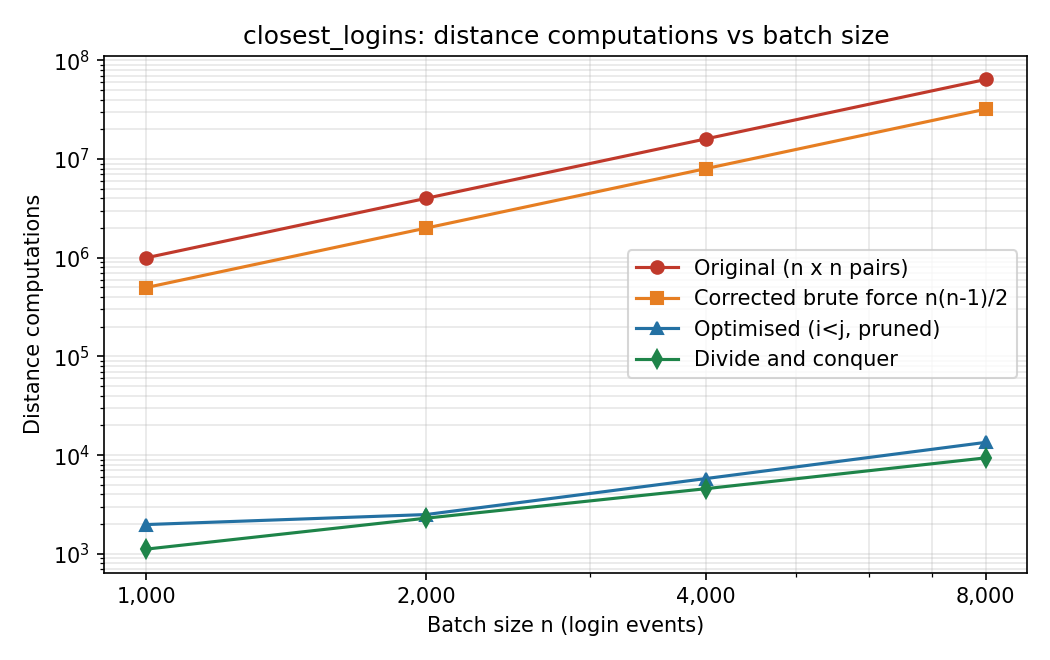

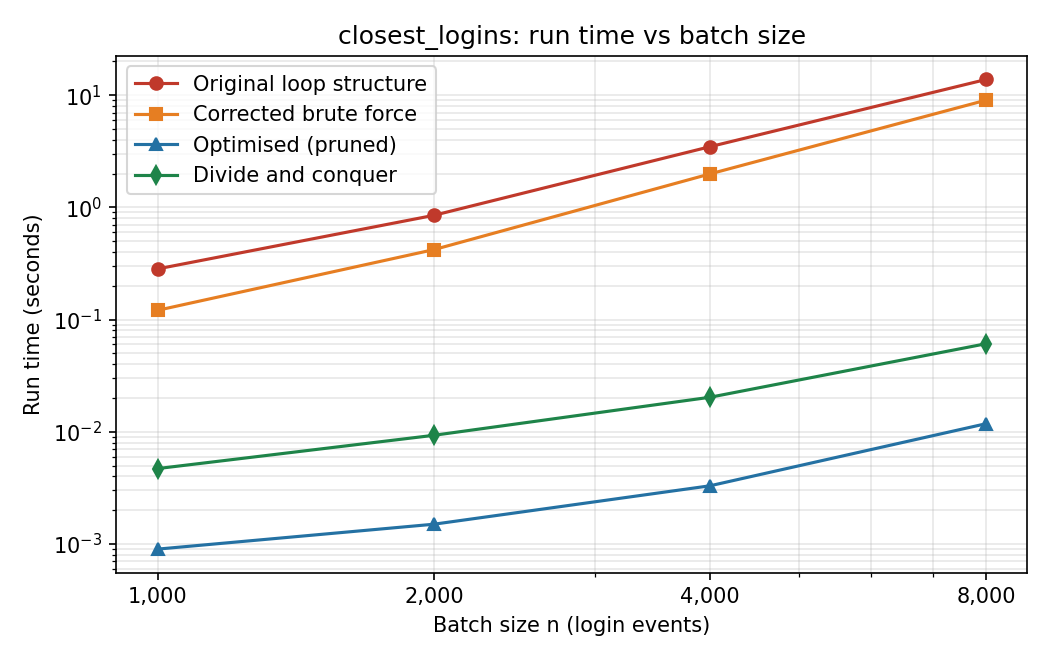

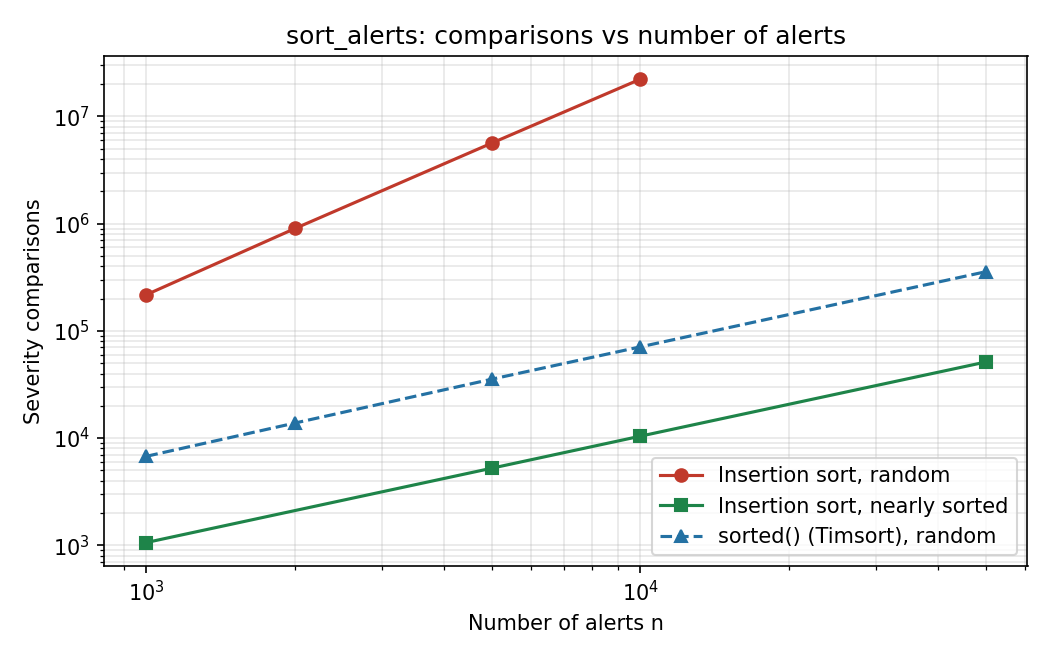

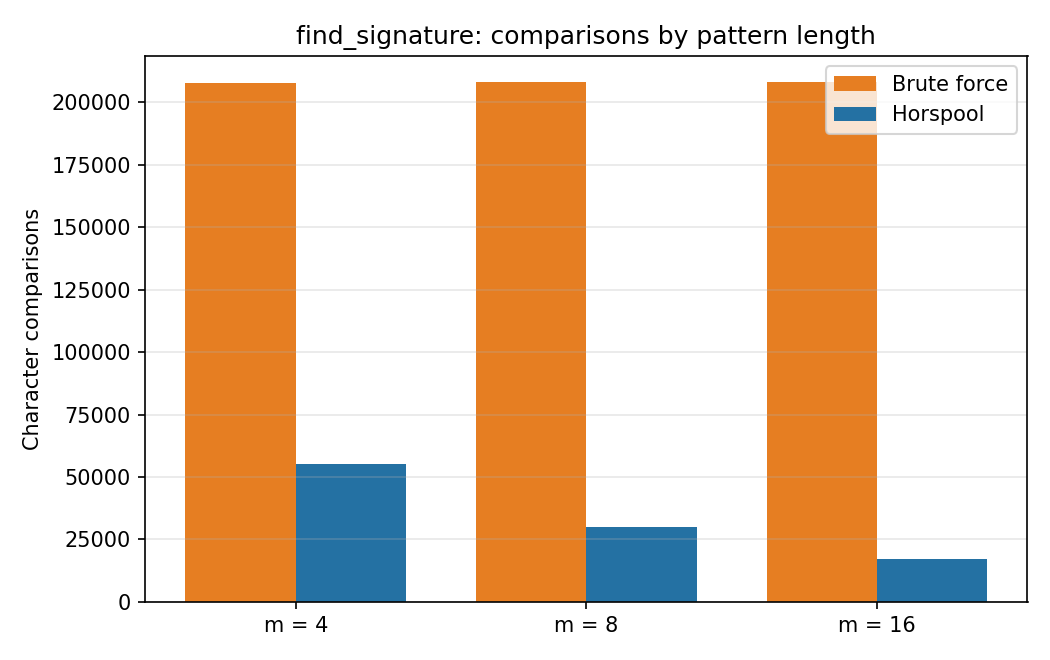

In [8]:
ex.make_graphs(sort_rows, block_rows, sig_rows, closest_rows)
for name in ("graph1_closest_pair_distance_computations.png", "graph2_closest_pair_run_time.png",
             "graph3_sort_comparisons.png", "graph4_signature_comparisons.png"):
    display(Image(filename=str(ex.ROOT / "graphs" / name), width=560))

## 7. Reading the results
* **Sorting:** on random data insertion sort needs about 0.225 n^2 comparisons (22 million at n = 10,000) while `sorted()` needs fewer than n log2 n; on nearly sorted data insertion sort needs exactly (shifts + n - 1) comparisons, i.e. about n, and `sorted()` needs between n and 2 n.
* **Blocklist:** the sequential search needs about 3n/4 comparisons per query for a half-present query mix; the hash set needs one lookup.
* **Signature search:** brute force makes about n x 27/26 comparisons on random text and exactly m(n - m + 1) on the worst case; Horspool makes about n/m x 1.1 on random text.
* **Closest pair:** the original loop makes n x n distance computations; the corrected brute force n(n-1)/2; the pruned scan about 1.3 n on random points but n^2/4 on two vertical lines; divide and conquer about 1.1 n on both.